# 2020 — GPT-3 and In-Context Learning

**Papers:** Tom Brown et al., *"Language Models are Few-Shot Learners"*, NeurIPS (2020) (GPT-3). The controlled experiment below follows Shivam Garg, Dimitris Tsipras, Percy Liang & Gregory Valiant, *"What Can Transformers Learn In-Context? A Case Study of Simple Function Classes"*, NeurIPS (2022). Mechanism studies: Olsson et al., *"In-context Learning and Induction Heads"* (2022); von Oswald et al., *"Transformers learn in-context by gradient descent"* (2023).

GPT-3 (175B parameters, 300B tokens) was trained only to predict the next token, exactly like GPT (notebook 41). Its surprise was **in-context learning**: show it a few input→output examples in the prompt, and it performs the task on a new input, with **no gradient update**:

```
sea otter => loutre de mer
cheese => fromage
peppermint => ?
```

Few-shot ability grew sharply with model size, and it changed how models are used: instead of fine-tuning a model per task, you write a prompt. It also raised a scientific question: what algorithm is a frozen network running inside its forward pass?

Language is too messy to answer that cleanly, so we use Garg et al.'s controlled version. Every training sequence is a **new, random linear function** $y = w^\top x$, $w\sim\mathcal N(0, I_d)$, presented as $(x_1, y_1, x_2, y_2, \dots)$. No single $w$ can be memorised. To predict $y_k$, the model must infer $w$ from the earlier pairs **in its context**. We can then compare it with the algorithms we know: least squares, nearest neighbours, and averaging.

![Diagram: GPT-3 and in-context learning (Brown et al., 2020)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/46_2020_gpt3_in_context_learning.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
D, K = 8, 24                                                                 # input dimension, examples per prompt
def sample_prompts(B, k=K, d=D, noise=0.0):
    x = torch.randn(B, k, d, device=device); w = torch.randn(B, d, 1, device=device)
    y = (x @ w).squeeze(-1) + noise * torch.randn(B, k, device=device)
    return x, y

class ICLTransformer(nn.Module):
    """GPT-style causal Transformer over the interleaved sequence x1, y1, x2, y2, ...; reads out ŷ_i at each x_i token."""
    def __init__(self, d_model=128, n_layers=4, heads=4):
        super().__init__()
        self.inp = nn.Linear(D + 1, d_model); self.pos = nn.Parameter(torch.randn(2 * K, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model, heads, 4 * d_model, dropout=0.0, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, n_layers); self.out = nn.Linear(d_model, 1)
    def forward(self, x, y):
        B, k, d = x.shape
        xs = torch.cat([x, torch.zeros(B, k, 1, device=x.device)], -1)                       # x token: [x, 0]
        ys = torch.cat([torch.zeros(B, k, d, device=x.device), y[..., None]], -1)            # y token: [0, y]
        seq = torch.stack([xs, ys], 2).view(B, 2 * k, d + 1)
        mask = nn.Transformer.generate_square_subsequent_mask(2 * k, device=x.device)
        h = self.tf(self.inp(seq) + self.pos[:2 * k], mask=mask, is_causal=True)
        return self.out(h[:, 0::2]).squeeze(-1)                                              # prediction made at each x token

def train(model, steps=6000, B=128, lr=3e-4):
    seed_everything(0); model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1); t0 = time.time()
    for s in range(steps):
        x, y = sample_prompts(B)
        loss = F.mse_loss(model(x, y), y); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M params, trained in {time.time() - t0:.0f}s, final loss {loss.item():.3f}")
    return model.eval()

models = {"1 layer": train(ICLTransformer(n_layers=1)), "4 layers": train(ICLTransformer(n_layers=4))}

/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3139/3237735785.py:13: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tf = nn.TransformerEncoder(layer, n_layers); self.out = nn.Linear(d_model, 1)


0.21M params, trained in 61s, final loss 7.482


/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3139/3237735785.py:13: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tf = nn.TransformerEncoder(layer, n_layers); self.out = nn.Linear(d_model, 1)


0.80M params, trained in 235s, final loss 1.853


## Error vs. number of in-context examples
For each prompt position $i$, the model predicts $y_i$ from the $i-1$ pairs before it. Error is normalised so that predicting 0 scores 1.0 (it is $\mathbb E[(y-\hat y)^2]/d$). Baselines see exactly the same examples:
- **least squares** (minimum-norm solution when $i-1 < d$): the optimal estimator for this task
- **3-nearest neighbours** and **averaging** ($\hat w = \frac1n\sum y_j x_j$)

Transformer, 1 layer     error with 4 / 8 / 16 / 23 examples in context: 0.927 / 0.785 / 0.944 / 0.905
Transformer, 4 layers    error with 4 / 8 / 16 / 23 examples in context: 0.511 / 0.147 / 0.021 / 0.011
least squares            error with 4 / 8 / 16 / 23 examples in context: 0.496 / 0.000 / 0.000 / 0.000
3-nearest neighbours     error with 4 / 8 / 16 / 23 examples in context: 1.123 / 0.714 / 0.641 / 0.501
averaging                error with 4 / 8 / 16 / 23 examples in context: 2.172 / 1.098 / 0.559 / 0.414


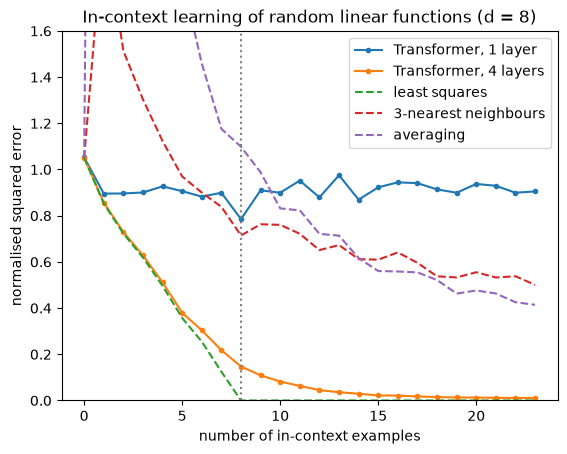

In [3]:
@torch.no_grad()
def baselines(x, y):
    B, k, d = x.shape; ls, knn, avg = torch.zeros(B, k), torch.zeros(B, k), torch.zeros(B, k)
    xc, yc = x.cpu().double(), y.cpu().double()
    for i in range(1, k):
        X, Y, q = xc[:, :i], yc[:, :i], xc[:, i]
        w = torch.linalg.pinv(X) @ Y[..., None]; ls[:, i] = (q[:, None] @ w).squeeze().float()
        dist = (X - q[:, None]).norm(dim=-1); nn_idx = dist.topk(min(3, i), largest=False).indices
        knn[:, i] = Y.gather(1, nn_idx).mean(1).float()
        avg[:, i] = (q * (Y[..., None] * X).mean(1)).sum(-1).float()
    return {"least squares": ls, "3-nearest neighbours": knn, "averaging": avg}

seed_everything(123); x, y = sample_prompts(2000)
with torch.no_grad(): preds = {f"Transformer, {k}": m(x, y).cpu() for k, m in models.items()}
preds.update(baselines(x, y)); yc = y.cpu()
for name, p in preds.items():
    err = ((p - yc) ** 2).mean(0) / D
    plt.plot(range(K), err.numpy(), marker="." if "Transformer" in name else None, ls="-" if "Transformer" in name else "--", label=name)
    print(f"{name:24s} error with 4 / 8 / 16 / 23 examples in context: {err[4]:.3f} / {err[8]:.3f} / {err[16]:.3f} / {err[23]:.3f}")
plt.axvline(D, c="gray", ls=":"); plt.ylim(0, 1.6); plt.xlabel("number of in-context examples"); plt.ylabel("normalised squared error")
plt.title(f"In-context learning of random linear functions (d = {D})"); plt.legend(); plt.show()

The 4-layer Transformer tracks least squares closely: its error falls steeply as examples accumulate and is near zero once the context holds more examples than dimensions ( > d$), which is what a model that is actually solving for $ in context should do. The 1-layer model, with the same training budget, does not learn the task at all (error stays near 1, the level of guessing 0). Capacity decides whether the forward pass can implement the algorithm, an echo of GPT-3's finding that few-shot ability appears with scale.
## Is it really learning from the context?
Two checks on the 4-layer model:
1. **Shuffle the $y$'s** in the context across prompts (the inputs stay the same, but the labels no longer follow any single $w$). If the model reads the examples, its error should become that of guessing.
2. **Distribution shift:** scale the query inputs by 2. Least squares is unaffected; a model that only memorised typical outputs is not.

In [4]:
m = models["4 layers"]
with torch.no_grad():
    base = ((m(x, y)[:, -1] - y[:, -1]) ** 2).mean().item() / D
    y_shuf = y.clone(); y_shuf[:, :-1] = y[torch.randperm(len(y), device=device), :-1]
    shuf = ((m(x, y_shuf)[:, -1] - y[:, -1]) ** 2).mean().item() / D
    x2, y2 = x.clone(), y.clone(); x2[:, -1] *= 2; y2[:, -1] *= 2                     # y = wᵀx is linear: doubling x doubles y
    shift = ((m(x2, y2)[:, -1] - y2[:, -1]) ** 2).mean().item() / D / 4
print(f"query error with {K - 1} real examples:          {base:.3f}")
print(f"query error with the context labels shuffled:  {shuf:.3f}   (≈ 1 means it relied on the examples)")
print(f"query error with the query input scaled ×2:     {shift:.3f}   (normalised by the larger output scale)")

query error with 23 real examples:          0.011
query error with the context labels shuffled:  1.520   (≈ 1 means it relied on the examples)
query error with the query input scaled ×2:     0.021   (normalised by the larger output scale)


## Takeaways
- **In-context learning is learning without weight updates.** Trained on many tasks, a Transformer's forward pass becomes a learning algorithm: here it approximates least squares on whatever examples are in the prompt.
- **Scale and depth matter**, as in GPT-3: the 1-layer model never learns to use its context; the 4-layer model does. Mechanistic work found induction heads (copying patterns from earlier in the context, Olsson et al. 2022) and showed linear attention can implement gradient-descent steps on in-context examples (von Oswald et al. 2023).
- **It generalises within limits.** Scaling the query input by 2 barely hurt here, but Garg et al. found that larger shifts (inputs far outside the training distribution, or prompts much longer than in training) break the learned algorithm while least squares is unaffected: a small-scale version of why prompting is powerful but brittle.
- GPT-3 also showed predictable gains from scale (notebook 45) and led to instruction tuning and RLHF (notebook 57), which made prompting reliable enough for ChatGPT.